# Praktikum 1


## KMeans


In [1]:
#Persiapan data

# !pip install pandas
# !pip install matplotlib
# !pip install scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('burnout_dataset1.csv')
df.fillna(df.mean(numeric_only=True), inplace=True)

df.head()


,Person_ID,Age,Gender,Country,Occupation,Education_Level,Employment_Status,Monthly_Income_USD,Work_Hours_Per_Week,Remote_Work,...,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Score,Mental_Health_Status,AI_Wellness_Recommendation,Burnout_Risk
0,1,58.0,Male,United States,Marketing Manager,Diploma,Employed,2786.000000,67,Hybrid,...,No,Yes,Average,6.0,19.0,2,82,Critical,Practice Mindfulness,High
1,2,24.0,Female,Pakistan,Freelancer,Bachelor,Student,8027.000000,44,Hybrid,...,Yes,No,Good,4.0,27.0,22,64,Critical,Reduce Workload,Moderate
2,3,59.0,Male,Malaysia,Accountant,PhD,Employed,3177.000000,60,No,...,Yes,No,Average,4.0,51.0,17,50,Needs Attention,Increase Physical Activity,Moderate
3,4,65.0,Other,Mexico,Chef,Master,Self-Employed,4093.000000,25,Yes,...,No,Yes,Good,7.0,83.0,14,16,Healthy,Maintain Healthy Routine,Low
4,5,64.0,Other,Japan,Farmer,Diploma,Student,6251.281524,52,No,...,Yes,No,Poor,9.0,61.0,4,26,Healthy,Reduce Workload,Low


In [2]:
#Seleksi Fitur
X = df[['Work_Hours_Per_Week', 'Job_Satisfaction', 'Work_Life_Balance', 'Burnout_Score']]
y = df['Burnout_Risk']

df.head()


,Person_ID,Age,Gender,Country,Occupation,Education_Level,Employment_Status,Monthly_Income_USD,Work_Hours_Per_Week,Remote_Work,...,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Score,Mental_Health_Status,AI_Wellness_Recommendation,Burnout_Risk
0,1,58.0,Male,United States,Marketing Manager,Diploma,Employed,2786.000000,67,Hybrid,...,No,Yes,Average,6.0,19.0,2,82,Critical,Practice Mindfulness,High
1,2,24.0,Female,Pakistan,Freelancer,Bachelor,Student,8027.000000,44,Hybrid,...,Yes,No,Good,4.0,27.0,22,64,Critical,Reduce Workload,Moderate
2,3,59.0,Male,Malaysia,Accountant,PhD,Employed,3177.000000,60,No,...,Yes,No,Average,4.0,51.0,17,50,Needs Attention,Increase Physical Activity,Moderate
3,4,65.0,Other,Mexico,Chef,Master,Self-Employed,4093.000000,25,Yes,...,No,Yes,Good,7.0,83.0,14,16,Healthy,Maintain Healthy Routine,Low
4,5,64.0,Other,Japan,Farmer,Diploma,Student,6251.281524,52,No,...,Yes,No,Poor,9.0,61.0,4,26,Healthy,Reduce Workload,Low


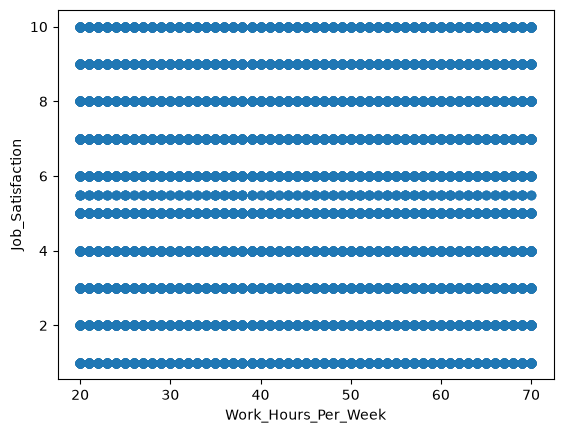

In [3]:
# Plot Data
# Karena data 4 dimensi, maka akan kita coba
# plot cluster berdasarkan Work_Hours_Per_Week dan Job_Satisfaction saja

plt.scatter(X.iloc[:, 0], X.iloc[:, 1], alpha=0.5)
plt.xlabel('Work_Hours_Per_Week')
plt.ylabel('Job_Satisfaction')
plt.show()


In [4]:
# Buat Model KMeans

from sklearn.cluster import KMeans

# Inisiasi obyek KMeans
cl_kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Fit dan predict model
y_kmeans = cl_kmeans.fit_predict(X)


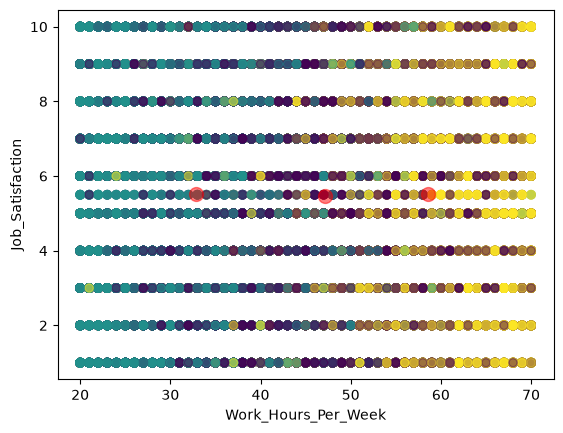

In [5]:
# Plot hasi cluster berdasarkan Work_Hours_Per_Week dan Job_Satisfaction
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=y_kmeans, alpha=0.5)

# Tampilkan centroid
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=100, alpha=0.5)
plt.xlabel('Work_Hours_Per_Week')
plt.ylabel('Job_Satisfaction')
plt.show()


In [6]:
# Cek Nilai SSE
print(f'Nilai SSE: {cl_kmeans.inertia_}')


Nilai SSE: 12207903.033942403


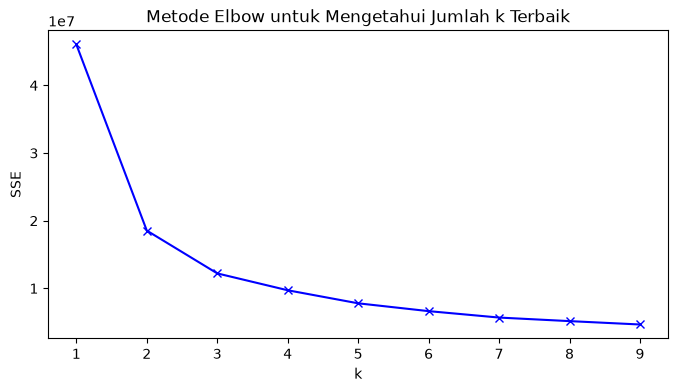

In [7]:
# Implementasi Metode Elbow

# List nilai SSE
sse = []

# Cari k terbaik dari 1-10
K = range(1, 10)

# Cek nilai SSE setiap k
for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeanModel.fit(X)
    sse.append(kmeanModel.inertia_)

# Plotting the distortions of prunning
plt.figure(figsize=(8,4))
plt.plot(K, sse, 'bx-')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Metode Elbow untuk Mengetahui Jumlah k Terbaik')
plt.show()


In [8]:
# Cek Nilai SSE setiap k
for idx, sse_val in enumerate(sse, start=1):
    print(f'k={idx}; SSE={sse_val}')


k=1; SSE=46041436.78718932
k=2; SSE=18535625.269216757
k=3; SSE=12207903.033942403
k=4; SSE=9714300.727138853
k=5; SSE=7785374.761975305
k=6; SSE=6629290.111659702
k=7; SSE=5680303.812183605
k=8; SSE=5153926.344429568
k=9; SSE=4654723.1132168155
